# DAR ES SALAAM INSTITUTE OF TECHNOLOGY

## DIGITAL SIGNAL PROCESSING LABORATORY

### WEEK 4 – z-TRANSFORM LABORATORY

### Poles, Zeros and Stability

**Module Code:** COU 07506

**Name:** Gwamaka A Mwakabuta

**Registration Number:** 240242462281

**Academic Year:** 2026/2027

**Semester:** I

**Unit:** Unit 2 – z-Transform, ROC, Inverse z-Transform and Stability

In [1]:
# ==========================================
# WEEK 4 - DSP LABORATORY
# ENVIRONMENT CONFIGURATION
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

from scipy import signal

from IPython.display import Audio, display

# Configure graph dimensions
plt.rcParams["figure.figsize"] = (9, 4)

print("WEEK 4 DSP ENVIRONMENT READY!")

print("NumPy:", np.__version__)

import scipy
print("SciPy:", scipy.__version__)

print("Matplotlib:", plt.matplotlib.__version__)

WEEK 4 DSP ENVIRONMENT READY!
NumPy: 2.5.5
SciPy: 1.18.1
Matplotlib: 3.11.2


## Task 4.1 – A Pole-Zero Plotting Function

### Objective

To develop a Python function that calculates and
plots the poles and zeros of a digital transfer
function. The task also involves plotting the
frequency response and checking system stability.

### Theory

The transfer function of a digital system is:

H(z) = B(z) / A(z)

Zeros are the roots of the numerator, while poles
are the roots of the denominator.

A causal digital system is stable when all its poles
are located inside the unit circle.

In [2]:

# ==========================================
# TASK 4.1 - POLE-ZERO PLOTTING FUNCTION
# ==========================================

def zplane(b, a, ax=None):

    # Calculate zeros, poles and gain
    z, p, k = signal.tf2zpk(b, a)

    # Get current axes if none is provided
    if ax is None:
        ax = plt.gca()

    # Generate unit circle coordinates
    theta = np.linspace(0, 2*np.pi, 400)

    # Plot unit circle
    ax.plot(
        np.cos(theta),
        np.sin(theta),
        "k--",
        linewidth=0.8,
        label="Unit circle"
    )

    # Plot zeros using circles
    ax.plot(
        z.real,
        z.imag,
        "o",
        markerfacecolor="none",
        markersize=9,
        label="Zeros"
    )

    # Plot poles using crosses
    ax.plot(
        p.real,
        p.imag,
        "x",
        markersize=9,
        markeredgewidth=2,
        label="Poles"
    )

    # Configure graph
    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Real")
    ax.set_ylabel("Imaginary")
    ax.grid(True)

    return z, p


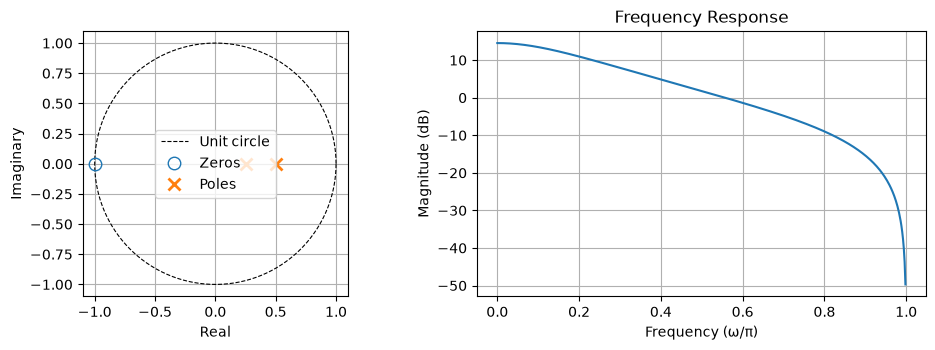

ZEROS: [-1.]
POLES: [0.5  0.25]
STABLE: True


In [3]:

# ==========================================
# TASK 4.1 - TEST THE TRANSFER FUNCTION
# ==========================================

# Define numerator and denominator
b = [1, 1]
a = [1, -0.75, 0.125]

# Create two graphs
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10, 3.6)
)

# Calculate and plot poles and zeros
z, p = zplane(b, a, ax1)

# Calculate frequency response
w, H = signal.freqz(b, a, worN=512)

# Calculate magnitude in decibels
magnitude_db = 20 * np.log10(
    np.maximum(np.abs(H), 1e-12)
)

# Plot frequency response
ax2.plot(w / np.pi, magnitude_db)

ax2.set_xlabel("Frequency (ω/π)")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_title("Frequency Response")
ax2.grid(True)

plt.tight_layout()
plt.show()

# Check stability
stable = np.all(np.abs(p) < 1)

# Display results
print("ZEROS:", z)
print("POLES:", p)
print("STABLE:", stable)



### Task 4.1 – Experimental Observations

In this experiment, I created a Python function
to calculate and plot the poles and zeros of a
digital system.

The system produced one zero at -1 and two poles
at 0.5 and 0.25.

The frequency-response graph showed that the
signal magnitude decreased as the frequency
increased towards the Nyquist frequency.

Both poles were inside the unit circle, so the
system was stable.

The experiment helped me understand how pole and
zero positions affect the frequency response
and stability of digital systems.


## Task 4.2 – Inverse z-Transform Using residuez()

### Objective

To calculate the inverse z-transform of a transfer
function using SciPy's residuez function and verify
the result using the lfilter function.

In [4]:

# ==========================================
# WEEK 4 - TASK 4.2
# INVERSE Z-TRANSFORM USING RESIDUEZ
# ==========================================

# Step 1: Define transfer function coefficients
b = [1]
a = [1, -0.75, 0.125]

# Step 2: Calculate residues, poles and direct term
r, p, k = signal.residuez(b, a)

# Display results
print("RESIDUES:", r)
print("POLES:", p)
print("DIRECT TERM:", k)


RESIDUES: [-1.  2.]
POLES: [0.25 0.5 ]
DIRECT TERM: []


In [5]:

# ==========================================
# TASK 4.2
# RECONSTRUCT INVERSE Z-TRANSFORM
# ==========================================

# Generate sample indices
n = np.arange(10)

# Calculate using partial fractions
x_pf = sum(
    ri * pi**n
    for ri, pi in zip(r, p)
).real

# Display reconstructed signal
print("INVERSE Z-TRANSFORM:")
print(x_pf)


INVERSE Z-TRANSFORM:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]


In [6]:

# ==========================================
# TASK 4.2
# VERIFY USING SCIPY LFILTER
# ==========================================

# Generate unit impulse
impulse = np.zeros(10)
impulse[0] = 1

# Calculate impulse response using lfilter
x_lf = signal.lfilter(
    b,
    a,
    impulse
)

print("PARTIAL-FRACTION RESULT:")
print(x_pf)

print("\nLFILTER RESULT:")
print(x_lf)

# Verify both methods
print("\nDo both results agree?")
print(np.allclose(x_pf, x_lf))


PARTIAL-FRACTION RESULT:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

LFILTER RESULT:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Do both results agree?
True


In [7]:

# ==========================================
# TASK 4.2
# REPEAT FOR TASK 4.1 SYSTEM
# ==========================================

# Transfer function coefficients
b2 = [1, 1]
a2 = [1, -0.75, 0.125]

# Calculate residues and poles
r2, p2, k2 = signal.residuez(b2, a2)

# Calculate inverse z-transform
h_pf = sum(
    ri * pi**n
    for ri, pi in zip(r2, p2)
).real

# Calculate using lfilter
h_lf = signal.lfilter(
    b2,
    a2,
    impulse
)

# Display results
print("RESIDUES:", r2)
print("POLES:", p2)

print("\nPARTIAL-FRACTION RESULT:")
print(h_pf)

print("\nLFILTER RESULT:")
print(h_lf)

print("\nVerification:")
print(np.allclose(h_pf, h_lf))


RESIDUES: [-5.  6.]
POLES: [0.25 0.5 ]

PARTIAL-FRACTION RESULT:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

LFILTER RESULT:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Verification:
True



### Task 4.2 – Experimental Observations

In this experiment, I used the residuez function
to calculate residues and poles of two transfer
functions.

I reconstructed their time-domain sequences using
the partial-fraction expansion.

I also used SciPy lfilter to calculate the same
sequences for comparison.

Both experiments produced matching results, and
the numerical verification returned True.

The first experiment produced residues of -1 and 2,
while the second produced residues of -5 and 6.

The experiment demonstrated how the inverse
z-transform can be calculated using partial
fractions and verified using digital filtering.


## Task 4.3 – Pole Position and the Impulse Response

### Objective

To investigate how changing the radius of complex
conjugate poles affects the impulse response,
frequency response, resonance and stability
of a digital system.

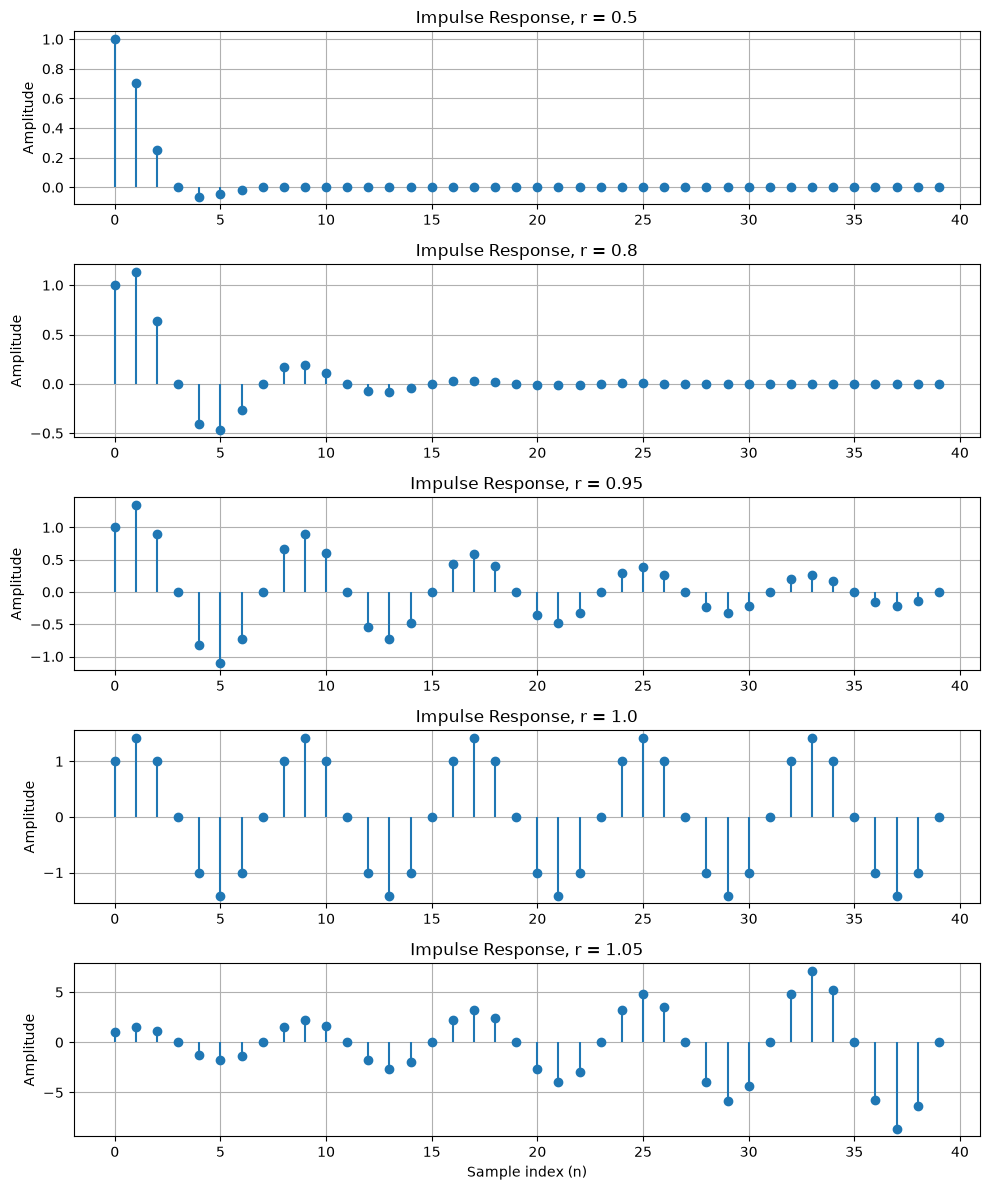

In [8]:

# ==========================================
# WEEK 4 - TASK 4.3
# POLE POSITION AND IMPULSE RESPONSE
# ==========================================

# Step 1: Define experimental parameters
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

theta = np.pi / 4

N = 40

# Generate unit impulse
impulse = np.zeros(N)
impulse[0] = 1

# Step 2: Create figure for impulse responses
fig, axes = plt.subplots(
    len(r_values), 1,
    figsize=(10, 12)
)

# Step 3: Investigate each pole radius
for ax, r in zip(axes, r_values):

    # Calculate denominator coefficients
    a = [
        1,
        -2 * r * np.cos(theta),
        r**2
    ]

    # Numerator coefficients
    b = [1]

    # Calculate impulse response
    h = signal.lfilter(b, a, impulse)

    # Plot impulse response
    ax.stem(
        np.arange(N),
        h,
        basefmt=" "
    )

    ax.set_title(f"Impulse Response, r = {r}")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

axes[-1].set_xlabel("Sample index (n)")

plt.tight_layout()
plt.show()


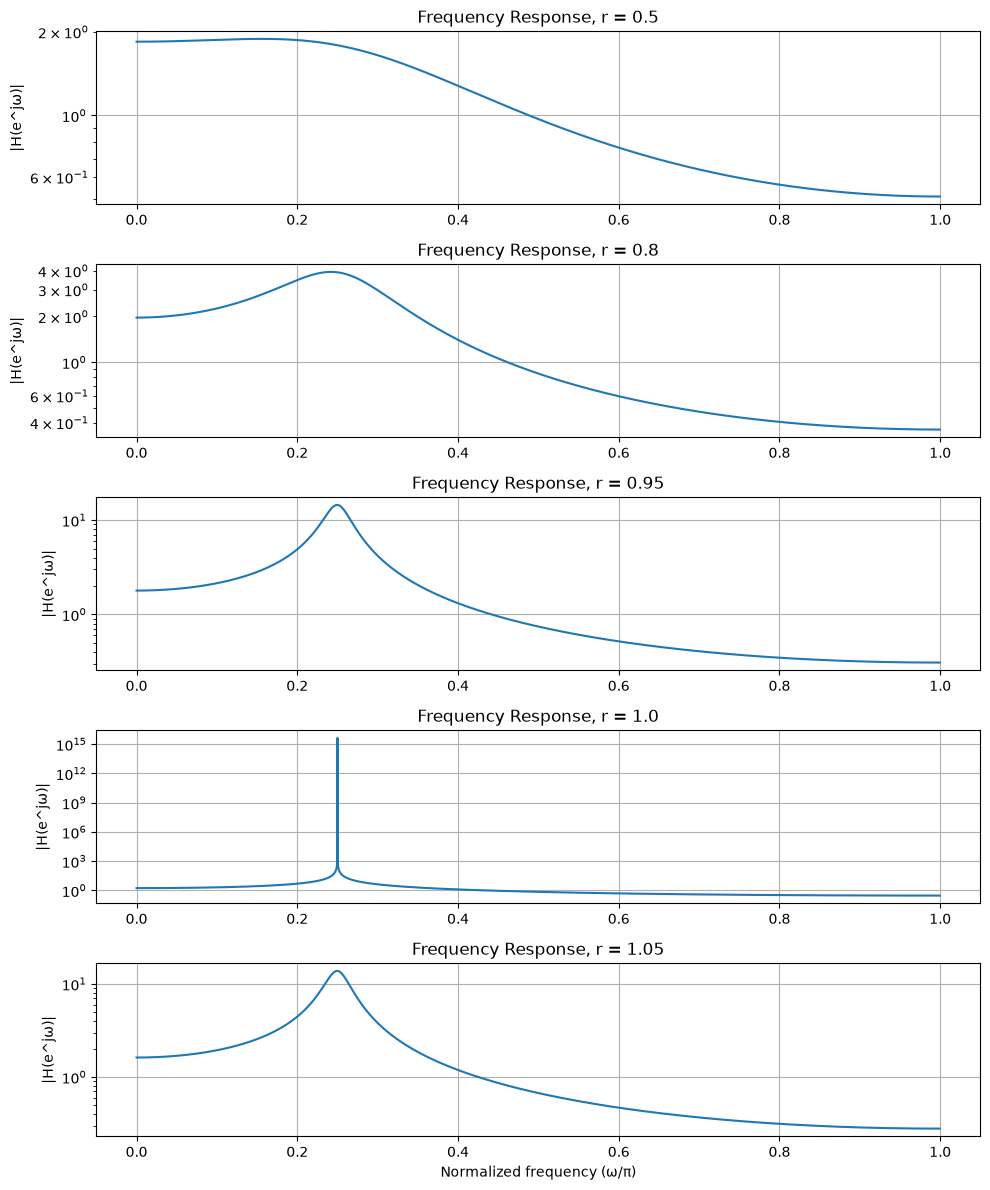

In [9]:

# ==========================================
# TASK 4.3
# FREQUENCY RESPONSE COMPARISON
# ==========================================

fig, axes = plt.subplots(
    len(r_values), 1,
    figsize=(10, 12)
)

for ax, r in zip(axes, r_values):

    # Calculate denominator coefficients
    a = [
        1,
        -2 * r * np.cos(theta),
        r**2
    ]

    b = [1]

    # Calculate frequency response
    w, H = signal.freqz(
        b,
        a,
        worN=2048
    )

    # Calculate magnitude
    magnitude = np.abs(H)

    # Plot magnitude on a logarithmic scale
    ax.semilogy(
        w / np.pi,
        magnitude
    )

    ax.set_title(f"Frequency Response, r = {r}")
    ax.set_ylabel("|H(e^jω)|")
    ax.grid(True)

axes[-1].set_xlabel("Normalized frequency (ω/π)")

plt.tight_layout()
plt.show()


In [10]:
# ==========================================
# TASK 4.3
# STABILITY CLASSIFICATION
# ==========================================

print("POLE RADIUS AND STABILITY")
print("-" * 45)

for r in r_values:

    stable = r < 1

    print(
        f"Pole radius: {r:<5} "
        f"Stable: {stable}"
    )

POLE RADIUS AND STABILITY
---------------------------------------------
Pole radius: 0.5   Stable: True
Pole radius: 0.8   Stable: True
Pole radius: 0.95  Stable: True
Pole radius: 1.0   Stable: False
Pole radius: 1.05  Stable: False



### Task 4.3 – Experimental Observations

In this experiment, I investigated how changing
the pole radius affects the impulse response
and frequency response of a digital system.

I tested five pole radii: 0.50, 0.80, 0.95,
1.00 and 1.05.

I observed that smaller pole radii produced
faster-decaying oscillations. As the radius
approached 1, the oscillations lasted longer.

At a radius of 1.00, the oscillations continued
without decaying, while at 1.05, their amplitude
increased with time.

The frequency-response graphs also showed that
the resonance peak became sharper and higher
as the pole radius approached 1.

The experiment demonstrated that pole position
affects the response and stability of a digital
system. Poles outside the unit circle produce
unstable systems.


## Task 4.4 – Stability of Given Systems

### Objective

To investigate the stability of four digital
systems by calculating their poles and zeros,
plotting their pole-zero diagrams and examining
their impulse responses.

STABILITY ANALYSIS

System: H1
Zeros: []
Poles: [0.8+0.5j 0.8-0.5j]
Pole magnitudes: [0.9434 0.9434]
Stable: True

System: H2
Zeros: [-1.]
Poles: [2.  0.5]
Pole magnitudes: [2.  0.5]
Stable: False

System: H3
Zeros: []
Poles: [-1.   0.5]
Pole magnitudes: [1.  0.5]
Stable: False

System: H4
Zeros: [-1.+0.j  0.+1.j  0.-1.j  1.+0.j]
Poles: []
Pole magnitudes: []
Stable: True


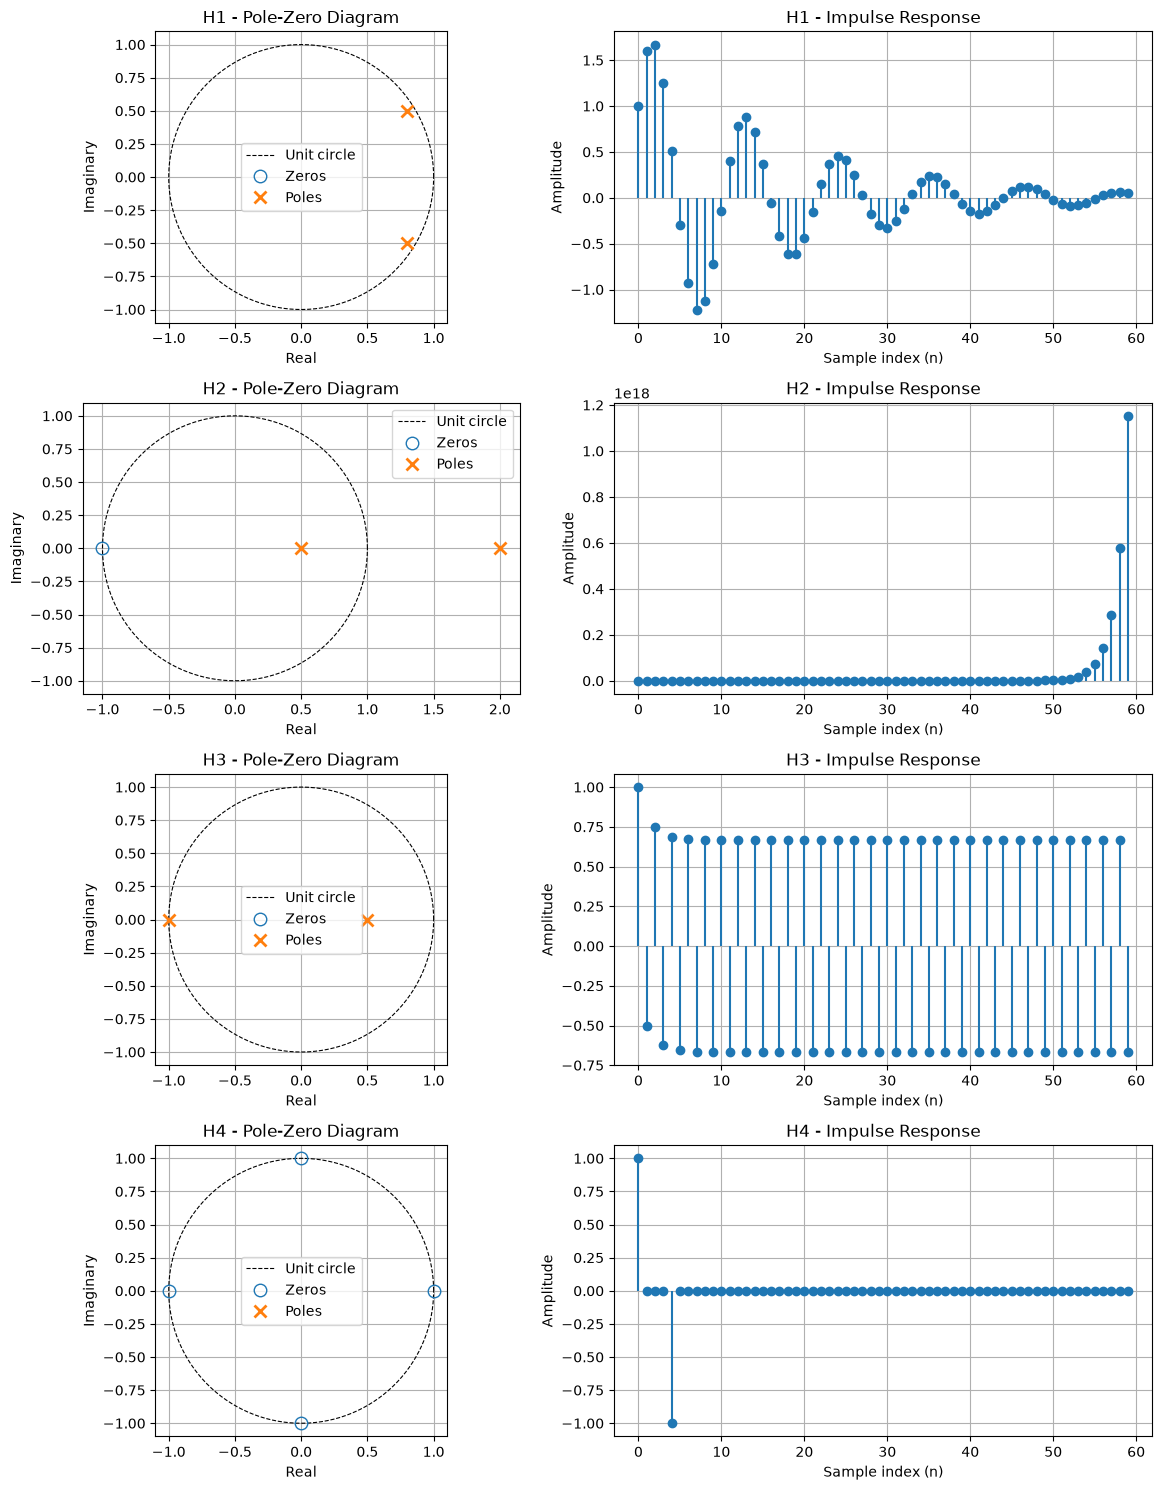

In [11]:

# ==========================================
# WEEK 4 - TASK 4.4
# STABILITY OF GIVEN SYSTEMS
# ==========================================

# Step 1: Define the four transfer functions

systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

# Step 2: Generate unit impulse
N = 60
impulse = np.zeros(N)
impulse[0] = 1

# Step 3: Prepare graphs
fig, axes = plt.subplots(
    4, 2,
    figsize=(12, 15)
)

print("STABILITY ANALYSIS")
print("=" * 55)

# Step 4: Analyse each system

for i, (name, coefficients) in enumerate(systems.items()):

    b_sys, a_sys = coefficients

    # Calculate poles and zeros
    z, p, k = signal.tf2zpk(b_sys, a_sys)

    # Determine stability
    stable = np.all(np.abs(p) < 1)

    # Calculate impulse response
    h = signal.lfilter(
        b_sys,
        a_sys,
        impulse
    )

    # Plot pole-zero diagram
    zplane(b_sys, a_sys, axes[i, 0])
    axes[i, 0].set_title(f"{name} - Pole-Zero Diagram")

    # Plot impulse response
    axes[i, 1].stem(
        np.arange(N),
        h,
        basefmt=" "
    )

    axes[i, 1].set_title(
        f"{name} - Impulse Response"
    )

    axes[i, 1].set_xlabel("Sample index (n)")
    axes[i, 1].set_ylabel("Amplitude")
    axes[i, 1].grid(True)

    # Display numerical results
    print(f"\nSystem: {name}")
    print("Zeros:", np.round(z, 4))
    print("Poles:", np.round(p, 4))
    print("Pole magnitudes:", np.round(np.abs(p), 4))
    print("Stable:", stable)

plt.tight_layout()
plt.show()



### Task 4.4 – Experimental Observations

In this experiment, I tested four digital systems
to determine their stability using pole-zero diagrams
and impulse responses.

System H1 was stable because both poles were inside
the unit circle, and its impulse response gradually
decreased.

System H2 was unstable because one pole was outside
the unit circle. Its impulse response increased with
time.

System H3 was not BIBO stable because one pole was
on the unit circle. Its impulse response continued
oscillating without decaying.

System H4 was stable because it had no poles and
produced a finite impulse response.

The experiment demonstrated that pole positions
determine the stability of digital systems.


## Task 4.5 – Design a Simple Resonator

### Objective

To design a second-order digital resonator
with a resonance frequency of 1,000 Hz,
a sampling frequency of 8,000 Hz and
a pole radius of 0.97.

The experiment also investigates the effect
of the resonator on white noise.

In [12]:

# ==========================================
# WEEK 4 - TASK 4.5
# DESIGN A SIMPLE RESONATOR
# ==========================================

# Step 1: Define design parameters
fs = 8000
f0 = 1000
r = 0.97

# Step 2: Calculate digital angular frequency
w0 = 2 * np.pi * f0 / fs

# Step 3: Calculate numerator coefficients
# Zeros are located at z = +1 and z = -1
b = [1, 0, -1]

# Step 4: Calculate denominator coefficients
# Poles are located at r * exp(+/-j*w0)
a = [
    1,
    -2 * r * np.cos(w0),
    r**2
]

# Step 5: Display design information
print("RESONATOR DESIGN PARAMETERS")
print("-" * 40)

print("Sampling frequency:", fs, "Hz")
print("Resonance frequency:", f0, "Hz")
print("Pole radius:", r)
print("Digital angular frequency:", w0)

print("\nNumerator coefficients:", b)
print("Denominator coefficients:", a)

# Step 6: Calculate poles and zeros
zeros, poles, gain = signal.tf2zpk(b, a)

print("\nZEROS:", zeros)
print("POLES:", poles)

# Step 7: Check stability
stable = np.all(np.abs(poles) < 1)

print("STABLE:", stable)


RESONATOR DESIGN PARAMETERS
----------------------------------------
Sampling frequency: 8000 Hz
Resonance frequency: 1000 Hz
Pole radius: 0.97
Digital angular frequency: 0.7853981633974483

Numerator coefficients: [1, 0, -1]
Denominator coefficients: [1, np.float64(-1.3717871555019023), 0.9409]

ZEROS: [-1.  1.]
POLES: [0.68589358+0.68589358j 0.68589358-0.68589358j]
STABLE: True


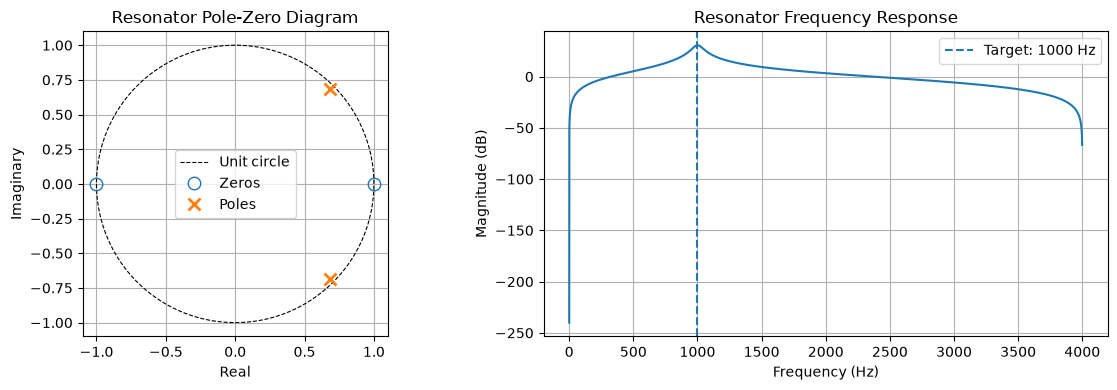

Target resonance frequency: 1000 Hz
Measured peak frequency: 1000.98 Hz


In [13]:

# ==========================================
# TASK 4.5
# POLE-ZERO DIAGRAM AND FREQUENCY RESPONSE
# ==========================================

# Create two plots
fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(12, 4)
)

# Plot pole-zero diagram
zplane(b, a, ax1)

ax1.set_title("Resonator Pole-Zero Diagram")

# Calculate frequency response in Hz
f, H = signal.freqz(
    b,
    a,
    worN=4096,
    fs=fs
)

# Calculate magnitude in dB
magnitude_db = 20 * np.log10(
    np.maximum(np.abs(H), 1e-12)
)

# Plot frequency response
ax2.plot(f, magnitude_db)

# Mark target frequency
ax2.axvline(
    f0,
    linestyle="--",
    label="Target: 1000 Hz"
)

ax2.set_title("Resonator Frequency Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

# Find actual peak frequency
peak_index = np.argmax(np.abs(H))

print("Target resonance frequency:", f0, "Hz")
print("Measured peak frequency:", round(f[peak_index], 2), "Hz")


In [14]:

# ==========================================
# TASK 4.5
# APPLY RESONATOR TO WHITE NOISE
# ==========================================

from IPython.display import Audio, display

# Step 1: Generate white noise
rng = np.random.default_rng(42)

noise = rng.standard_normal(fs * 2)

# Step 2: Apply the resonator
y = signal.lfilter(b, a, noise)

# Step 3: Display information
print("INPUT SIGNAL: WHITE NOISE")
print("Number of samples:", len(noise))

print("\nFILTERED SIGNAL:")
print("Number of samples:", len(y))
print("Sampling frequency:", fs, "Hz")

# Step 4: Listen to filtered output
display(Audio(y, rate=8000))


INPUT SIGNAL: WHITE NOISE
Number of samples: 16000

FILTERED SIGNAL:
Number of samples: 16000
Sampling frequency: 8000 Hz


### Listening Observation

After passing white noise through the resonator, I heard a noisy sound with a noticeable high-pitched, whistle-like tone.

The output was not completely clear because some noise was still present.

This happened because the resonator emphasized frequencies around 1,000 Hz while reducing other frequency components.

The listening result agreed with the frequency-response graph, which showed a peak close to 1,000 Hz.

Therefore, the experiment demonstrated how a digital resonator can emphasize a selected frequency in a signal.


# WEEK 4 – ANALYSIS QUESTIONS
## Poles, Zeros and Stability

### Question 1: Effect of Pole Radius on Resonance Bandwidth

The value of the pole radius (r) affects the bandwidth of a resonator.

- When r = 0.5, the resonance is broad and the impulse response decays quickly.
- When r = 0.8, the resonance becomes narrower.
- When r = 0.95, the resonance becomes sharper and the impulse response takes longer to decay.
- When r = 1.0, the pole lies on the unit circle and the impulse response does not decay.
- When r = 1.05, the system becomes unstable because the pole is outside the unit circle.

Therefore, as r approaches 1, the resonance becomes sharper and its bandwidth becomes narrower.

### Question 2: Pole on the Unit Circle

When a pole lies exactly on the unit circle, its magnitude is equal to 1.

The impulse response does not decay with time. Instead, it produces a continuous oscillation.

Such a system is not BIBO stable because its impulse response is not absolutely summable.

Therefore, a causal system with a pole on the unit circle is not stable.

### Question 3: Why Zeros at z = +1 and z = -1 Produce a Band-Pass Response

Placing zeros at z = +1 and z = -1 helps suppress unwanted frequency components.

- A zero at z = +1 blocks DC (0 Hz).
- A zero at z = -1 blocks the Nyquist frequency (half the sampling frequency).

The resonator poles increase the response around the selected resonance frequency.

Therefore, the combination of these zeros and poles produces a band-pass response, allowing frequencies around the resonance frequency to pass while attenuating DC and Nyquist components.

### Question 4: Stability Triangle

For a second-order denominator:

A(z) = 1 + a1*z^-1 + a2*z^-2

The stability conditions are:

1. 1 + a1 + a2 > 0
2. 1 - a1 + a2 > 0
3. 1 - a2 > 0

Applying these conditions:

**System H1**

Denominator: 1 - 1.6z^-1 + 0.89z^-2

- 1 - 1.6 + 0.89 = 0.29 > 0
- 1 + 1.6 + 0.89 = 3.49 > 0
- 1 - 0.89 = 0.11 > 0

Result: Stable.

**System H2**

Denominator: 1 - 2.5z^-1 + z^-2

- 1 - 2.5 + 1 = -0.5
- 1 + 2.5 + 1 = 4.5 > 0
- 1 - 1 = 0

Result: Unstable because the first and third conditions are not satisfied.

**System H3**

Denominator: 1 + 0.5z^-1 - 0.5z^-2

- 1 + 0.5 - 0.5 = 1 > 0
- 1 - 0.5 - 0.5 = 0
- 1 + 0.5 = 1.5 > 0

Result: Unstable because the second condition is not strictly satisfied.

**Conclusion:**

The stability triangle confirms the results obtained from the pole-zero diagrams:

- H1: Stable.
- H2: Unstable.
- H3: Unstable.


# WEEK 4 – OVERALL EXPERIMENTAL OBSERVATION

During Week 4, I performed experiments on pole-zero
diagrams, inverse Z-transforms, system stability
and digital resonator design.

I learned how pole and zero positions affect the
behaviour and stability of digital systems.

I also observed that stable systems produce
decaying or finite impulse responses, while unstable
systems can produce increasing responses.

In the final experiment, I designed a digital
resonator with a target frequency of 1,000 Hz.
The measured peak frequency was 1,000.98 Hz.

After filtering white noise, I heard a noisy sound
with a whistle-like tone, showing that the resonator
emphasized frequencies around its target frequency.

Overall, these experiments improved my understanding
of digital filters, system stability and frequency
response using Python.